# Campus Placement Prediction Using Machine Learning

## Introduction

Campus placement is an important part of a student's career. Placement depends on different factors, such as academic marks, CGPA, internships, training, communication skills, and technical courses.

The aim of this project is to use Machine Learning to predict whether a student is likely to be placed or not placed based on the available student details.

## Objectives

1. To understand the student placement dataset.
2. To perform data preprocessing.
3. To analyze the dataset using graphs.
4. To train and compare different classification algorithms.
5. To evaluate the models and identify which model performs better.


## 1. Importing Libraries

Libraries are collections of ready-made functions. In this project, Pandas is used to handle data, Matplotlib is used to create graphs, and Scikit-learn is used to train and evaluate Machine Learning models.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, confusion_matrix


## 2. Loading the Dataset

A dataset is a collection of data arranged in rows and columns. We will upload the CSV file and read it using Pandas so that we can work with the student information.

In [3]:



df = pd.read_csv("Sample.csv")

print("Dataset loaded successfully.")
print("Number of rows and columns:", df.shape)
df.head()


Dataset loaded successfully.
Number of rows and columns: (401, 16)


,Email,Name,Gender,10th board,10th marks,12th board,12th marks,Stream,Cgpa,Internships(Y/N),Training(Y/N),Backlog in 5th sem,Innovative Project(Y/N),Communication level,Technical Course(Y/N),Placement(Y/N)?
0,payal_roy79@gmail.com,Payal Roy,Female,State Board,96.7,CBSE,70.2,Mechanical Engineering,7.37,No,Yes,No,No,3,Yes,Not Placed
1,shreyoshi_dey13@gmail.com,Shreyoshi Dey,Female,WBBSE,96.2,WBCHSE,90.6,Electronics and Communication Engineering,9.35,No,No,No,Yes,4,No,Not Placed
2,rohan_nandi12@gmail.com,Rohan Nandi,Male,State Board,97.5,CBSE,69.6,Information Technology,7.84,No,Yes,No,Yes,3,Yes,Placed
3,smita_agarwal90@gmail.com,Smita Agarwal,Female,CBSE,96.9,Other state Board,77.6,Computer Science in AIML,7.87,Yes,No,Yes,Yes,2,Yes,Not Placed
4,samaira_singhania95@gmail.com,Samaira Singhania,Female,ICSE,99.1,CBSE,62.8,Computer Science and Engineering,9.26,Yes,Yes,No,Yes,1,Yes,Not Placed


## 3. Understanding the Dataset

Before building a model, we need to understand the data. We will check the number of records, column names, data types, missing values, and placement results.

In [4]:

print("Dataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nPlacement count:")
print(df["Placement(Y/N)?"].value_counts())


Dataset shape:
(401, 16)

Column names:
Index(['Email', 'Name', 'Gender', '10th board', '10th marks', '12th board',
       '12th marks', 'Stream', 'Cgpa', 'Internships(Y/N)', 'Training(Y/N)',
       'Backlog in 5th sem', 'Innovative Project(Y/N)', 'Communication level',
       'Technical Course(Y/N)', 'Placement(Y/N)?'],
      dtype='object')

Data types:
Email                       object
Name                        object
Gender                      object
10th board                  object
10th marks                 float64
12th board                  object
12th marks                 float64
Stream                      object
Cgpa                       float64
Internships(Y/N)            object
Training(Y/N)               object
Backlog in 5th sem          object
Innovative Project(Y/N)     object
Communication level          int64
Technical Course(Y/N)       object
Placement(Y/N)?             object
dtype: object

Missing values:
Email                      0
Name                  

## 4. Data Preprocessing

Data preprocessing means preparing the data before training a Machine Learning model.

In this step, we will remove personal details such as name and email, make category labels consistent, check invalid CGPA values, and convert text categories into numerical columns so that the algorithms can use them.

In [6]:

# Make a copy of the original dataset
df = df.copy()

# Remove personal details
df = df.drop(columns=["Email", "Name"], errors="ignore")

# Remove extra spaces from text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Make Yes/No values consistent
yes_no_columns = [
    "Internships(Y/N)",
    "Training(Y/N)",
    "Backlog in 5th sem",
    "Innovative Project(Y/N)",
    "Technical Course(Y/N)"
]

for col in yes_no_columns:
    df[col] = df[col].str.lower().replace({
        "yes": "Yes",
        "yess": "Yes",
        "no": "No",
        "y": "Yes",
        "n": "No"
    })

# Check CGPA values outside the expected 0-10 range
print("Invalid CGPA records:")
print(df[df["Cgpa"] > 10][["Cgpa"]])

# Treat CGPA values above 10 as invalid
df.loc[df["Cgpa"] > 10, "Cgpa"] = np.nan

# Fill missing CGPA with the median CGPA
df["Cgpa"] = df["Cgpa"].fillna(df["Cgpa"].median())

print("\nPreprocessing completed.")
print("Missing values after preprocessing:")
print(df.isnull().sum())


Invalid CGPA records:
     Cgpa
118  90.0

Preprocessing completed.
Missing values after preprocessing:
Gender                     0
10th board                 0
10th marks                 0
12th board                 0
12th marks                 0
Stream                     0
Cgpa                       0
Internships(Y/N)           0
Training(Y/N)              0
Backlog in 5th sem         0
Innovative Project(Y/N)    0
Communication level        0
Technical Course(Y/N)      0
Placement(Y/N)?            0
dtype: int64


## 5. Exploratory Data Analysis

Exploratory Data Analysis (EDA) means studying the dataset using tables and graphs. It helps us understand patterns in the data and the relationship between student details and placement results.

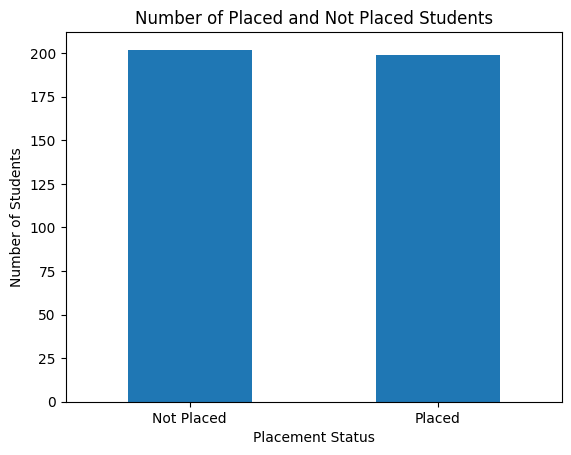

In [7]:

df["Placement(Y/N)?"].value_counts().plot(
    kind="bar",
    title="Number of Placed and Not Placed Students"
)

plt.xlabel("Placement Status")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()


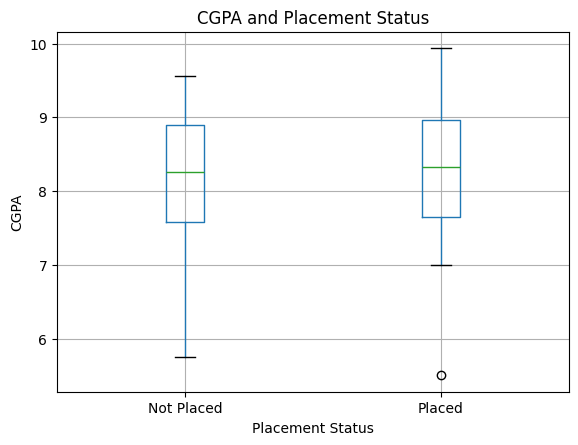

In [8]:

df.boxplot(column="Cgpa", by="Placement(Y/N)?")

plt.title("CGPA and Placement Status")
plt.suptitle("")
plt.xlabel("Placement Status")
plt.ylabel("CGPA")
plt.show()


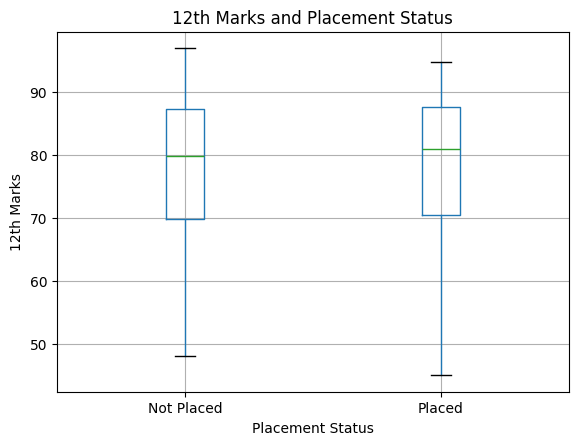

In [9]:

df.boxplot(column="12th marks", by="Placement(Y/N)?")

plt.title("12th Marks and Placement Status")
plt.suptitle("")
plt.xlabel("Placement Status")
plt.ylabel("12th Marks")
plt.show()


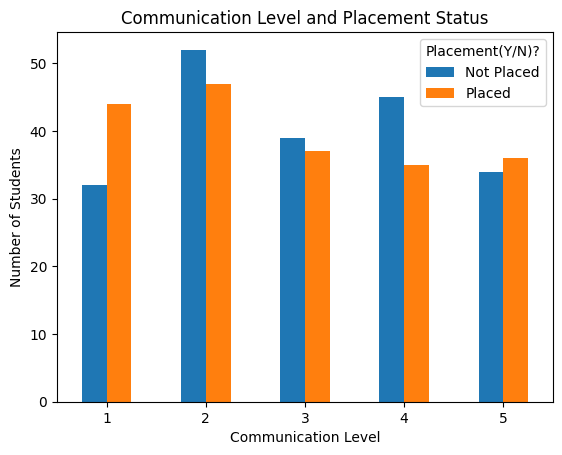

In [10]:

pd.crosstab(
    df["Communication level"],
    df["Placement(Y/N)?"]
).plot(kind="bar")

plt.title("Communication Level and Placement Status")
plt.xlabel("Communication Level")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()


## 6. Preparing Data for Training

The target variable is `Placement(Y/N)?`. The other selected columns are the input features used to predict placement.

Machine Learning algorithms work with numerical data. Therefore, we will convert text categories into numerical columns and divide the data into training and testing sets. The training data is used to teach the model, while the testing data is used to check its performance.

In [11]:

# Separate input features and target
X = df.drop(columns=["Placement(Y/N)?", "Gender"], errors="ignore")
y = df["Placement(Y/N)?"].str.strip().str.lower().map({
    "placed": 1,
    "not placed": 0
})

# Convert text categories into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Remove any rows with an invalid target
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Number of input features:", X_train.shape[1])


Training records: 320
Testing records: 81
Number of input features: 37


## 7. Model Training

Classification is a type of Machine Learning used to predict categories. In this project, the categories are Placed and Not Placed.

We will train three classification algorithms:

1. Logistic Regression
2. Decision Tree
3. Random Forest

We will use the same training data for all three models so that we can compare their results.

In [12]:

# Create the models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

# Train each model
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully.")


Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


## 8. Model Evaluation

Model evaluation helps us understand how well a model predicts placement.

We will use the following measures:

- **Accuracy:** The percentage of correct predictions.
- **Precision:** How many students predicted as placed were actually placed.
- **Recall:** How many actually placed students were correctly identified.
- **F1-score:** A combined measure of precision and recall.
- **Confusion matrix:** A table comparing actual results with predicted results.

In [13]:

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 3),
        "Precision": round(precision_score(
            y_test, y_pred, zero_division=0
        ), 3),
        "Recall": round(recall_score(
            y_test, y_pred, zero_division=0
        ), 3),
        "F1-Score": round(f1_score(
            y_test, y_pred, zero_division=0
        ), 3)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1-Score", ascending=False
)

print("Model Comparison:")
results_df


Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
2,Random Forest,0.901,0.881,0.925,0.902
0,Logistic Regression,0.889,0.860,0.925,0.892
1,Decision Tree,0.877,0.895,0.850,0.872


## 9. Confusion Matrix

A confusion matrix compares the actual placement results with the results predicted by the model. It helps us see correct and incorrect predictions for both classes.

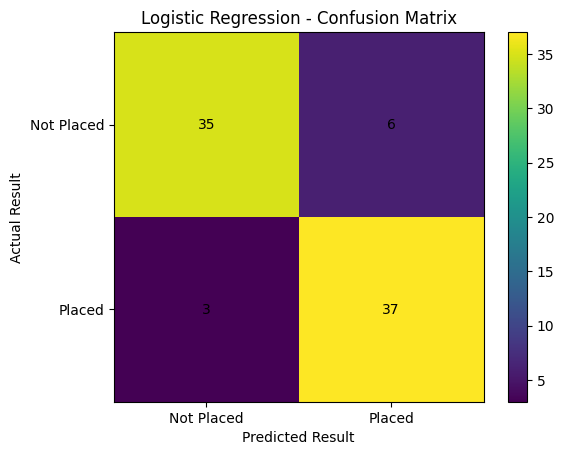

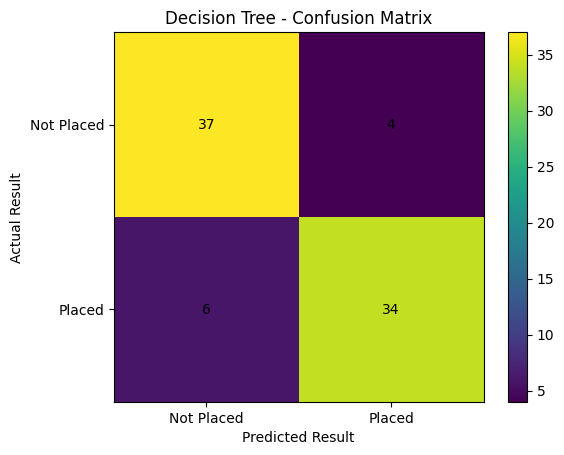

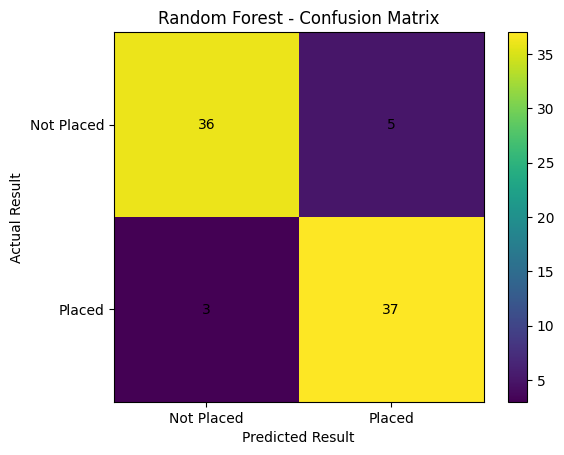

In [15]:

for name, model in models.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure()
    plt.imshow(cm)
    plt.title(name + " - Confusion Matrix")
    plt.xlabel("Predicted Result")
    plt.ylabel("Actual Result")
    plt.xticks([0, 1], ["Not Placed", "Placed"])
    plt.yticks([0, 1], ["Not Placed", "Placed"])

    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j],
                     ha="center", va="center")

    plt.colorbar()
    plt.show()


## 10. Feature Importance

Feature importance helps us understand which input features a trained model uses most when making predictions. We will use the Decision Tree model to display its feature importance values.

These values show the model's use of features; they do not prove that a feature causes placement.

                               Feature  Importance
35         Innovative Project(Y/N)_Yes    0.323760
36           Technical Course(Y/N)_Yes    0.164301
34              Backlog in 5th sem_Yes    0.155393
2                                 Cgpa    0.110482
0                           10th marks    0.080281
1                           12th marks    0.049808
18  Stream_Computer Science and Design    0.021834
33                   Training(Y/N)_Yes    0.012500
8                     12th board_CISCE    0.011980
11                      12th board_ISC    0.011021


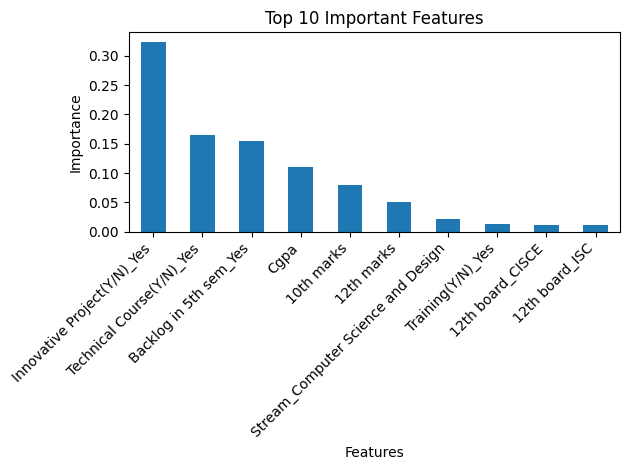

In [16]:

tree_model = models["Decision Tree"]

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": tree_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
).head(10)

print(importance)

importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    legend=False,
    title="Top 10 Important Features"
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 11. Conclusion

In this project, we used student academic and skill-related information to predict campus placement using Machine Learning classification algorithms.

We performed data preprocessing, created graphs, trained three classification models, and compared their performance using accuracy, precision, recall, F1-score, and confusion matrices.

The model with the best evaluation results will be selected for further consideration. The predictions are estimates based on the available dataset and are not a guarantee of actual placement.